# Análisis de clasificaciones por día

Este notebook analiza uno o varios archivos JSON generados por el pipeline de clasificación de comentarios de YouTube.

Objetivos:

- validar que cada run es completa y estructuralmente coherente;
- describir el **tono/sentimiento** de los comentarios;
- analizar intención, metaconversación y emoción;
- estudiar la confianza del clasificador;
- relacionar las categorías con `like_count`, `reply_count` y el momento de publicación;
- comparar los resultados entre días cuando haya más de un JSON disponible.

El notebook **no modifica** los JSON de clasificación ni la base SQLite original.


## 1. Imports y configuración

Ajusta únicamente las rutas de `RUN_FILES`.

Si el segundo día todavía no ha terminado, puedes dejar su ruta definida: el notebook ignorará temporalmente los archivos que aún no existan.


In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)


In [12]:
import os
print(os.getcwd())

C:\Users\lrenzullis\Desktop\REFIGURA\audiovisuales\notebooks


In [15]:
RUN_FILES = {
    "dia_1": Path("../datos/clasificacion_dia_1.json"),
    "dia_2": Path("../data/clasificaciones/clasificacion_dia_2.json"),
}

existing_runs = {
    run_name: path
    for run_name, path in RUN_FILES.items()
    if path.exists()
}

missing_runs = {
    run_name: path
    for run_name, path in RUN_FILES.items()
    if not path.exists()
}

print("Runs disponibles:")
for name, path in existing_runs.items():
    print(f"  {name}: {path}")

if missing_runs:
    print("\nRuns todavía no disponibles:")
    for name, path in missing_runs.items():
        print(f"  {name}: {path}")

assert existing_runs, "No se ha encontrado ningún JSON. Revisa RUN_FILES."


Runs disponibles:
  dia_1: ..\datos\clasificacion_dia_1.json

Runs todavía no disponibles:
  dia_2: ..\data\clasificaciones\clasificacion_dia_2.json


## 2. Funciones de carga y normalización

Cada comentario se convierte en una fila. Las variables multilabel (`Intention`, `Metaconversation` y `Emotion`) se conservan como listas.

Además se crea una columna `run` para poder comparar días posteriormente.


In [16]:
def load_run(path: Path, run_name: str):
    with path.open("r", encoding="utf-8") as f:
        raw = json.load(f)

    config = raw.get("config", {})
    results = raw.get("resultados", [])

    rows = []
    for item in results:
        analysis = item.get("analysis") or {}

        rows.append({
            "run": run_name,
            "video_id": item.get("video_id"),
            "comment_id": item.get("comment_id"),
            "parent_id": item.get("parent_id"),
            "text": item.get("text"),
            "published_at": item.get("published_at"),
            "updated_at": item.get("updated_at"),
            "like_count": item.get("like_count"),
            "reply_count": item.get("reply_count"),
            "Tone": analysis.get("Tone"),
            "Intention": analysis.get("Intention") or [],
            "Metaconversation": analysis.get("Metaconversation") or [],
            "Emotion": analysis.get("Emotion") or [],
            "Confidence": analysis.get("Confidence"),
        })

    df = pd.DataFrame(rows)

    if not df.empty:
        df["published_at"] = pd.to_datetime(df["published_at"], utc=True, errors="coerce")
        df["updated_at"] = pd.to_datetime(df["updated_at"], utc=True, errors="coerce")
        df["date"] = df["published_at"].dt.date
        df["hour"] = df["published_at"].dt.hour
        df["text_length"] = df["text"].fillna("").str.len()

    metadata = {
        "run": run_name,
        "path": str(path),
        "completo": raw.get("completo"),
        "n_resultados": len(results),
        **config,
    }

    return df, metadata


In [17]:
run_frames = []
run_metadata = []

for run_name, path in existing_runs.items():
    frame, metadata = load_run(path, run_name)
    run_frames.append(frame)
    run_metadata.append(metadata)

df = pd.concat(run_frames, ignore_index=True)
metadata_df = pd.DataFrame(run_metadata)

display(metadata_df)
print(f"\nComentarios cargados: {len(df):,}")


,run,path,completo,n_resultados,video_id,obra,estreno,modelo,lote,limite,reasoning_effort,max_output_tokens,entrada_sha256,desde_fecha,hasta_fecha,prompt_sha256,esquema_sha256
0,dia_1,..\datos\clasificacion_dia_1.json,True,5686,x8UAUAuKNcU,Lord of The Rings: rings of Power,None,gpt-6-luna,20,None,medium,16384,de652bf9a0496e089c3f68b00f1f77154a59be3d328838...,None,2022-08-23,1e1a9e79c6577304681029c9161021d491cf91bd085580...,ada85465cfbad5873db05a9ac2d85c5e3f90f6d7495a9a...



Comentarios cargados: 5,686


## 3. Control de calidad de las runs

Antes de interpretar resultados conviene comprobar:

- número de comentarios por run;
- IDs duplicados;
- fechas inválidas;
- tonos ausentes;
- valores de confianza ausentes o negativos;
- consistencia temporal de cada archivo.

Los casos con `Confidence < 0` se tratan como clasificaciones no válidas para los análisis interpretativos.


In [18]:
quality = (
    df.groupby("run")
    .agg(
        n_comments=("comment_id", "size"),
        unique_comments=("comment_id", "nunique"),
        first_comment=("published_at", "min"),
        last_comment=("published_at", "max"),
        invalid_dates=("published_at", lambda s: s.isna().sum()),
        missing_tone=("Tone", lambda s: s.isna().sum()),
        missing_confidence=("Confidence", lambda s: s.isna().sum()),
        negative_confidence=("Confidence", lambda s: (s < 0).sum()),
    )
)

quality["duplicated_ids"] = quality["n_comments"] - quality["unique_comments"]
display(quality)


,n_comments,unique_comments,first_comment,last_comment,invalid_dates,missing_tone,missing_confidence,negative_confidence,duplicated_ids
run,,,,,,,,,
dia_1,5686,5686,2022-08-23 13:01:11+00:00,2022-08-23 23:59:42+00:00,0,34,0,34,0


In [19]:
invalid_classifications = df[
    df["Tone"].isna()
    | df["Confidence"].isna()
    | (df["Confidence"] < 0)
].copy()

print(f"Clasificaciones no válidas: {len(invalid_classifications):,}")
display(
    invalid_classifications[
        ["run", "comment_id", "text", "Tone", "Confidence"]
    ].head(20)
)


Clasificaciones no válidas: 34


,run,comment_id,text,Tone,Confidence
884,dia_1,UgyTYPzr5Fx__MbdP2l4AaABAg,🤣🤣🤣🤣🤣🤣,NaN,-1
1131,dia_1,UgxFIGIbbX1FUu-js5x4AaABAg,se picoo,NaN,-1
1190,dia_1,UgxLGDUUN0nkCANZtKl4AaABAg,lol,NaN,-1
1275,dia_1,UgwJJjbRy495TGd-3ZZ4AaABAg,🫤,NaN,-1
1654,dia_1,Ugxc0D99ppLJRQho4tt4AaABAg,Memebumps.,NaN,-1
1704,dia_1,Ugw7MjekUTQMFZA-B-l4AaABAg,u s,NaN,-1
2001,dia_1,Ugz7wtyAdW3slR8XyJJ4AaABAg,OMG,NaN,-1
2259,dia_1,UgxD7buqF5-BEe2c8ux4AaABAg,LOTRINO.,NaN,-1
2417,dia_1,Ugxh6XF24kUFF_v6c8p4AaABAg,HFS!,NaN,-1
2448,dia_1,UgwaszTvG_vtHjjY_NJ4AaABAg,"Ish kakui, ai darûg nûl!",NaN,-1


In [20]:
valid = df[
    df["Tone"].notna()
    & df["Confidence"].notna()
    & (df["Confidence"] >= 0)
].copy()

print(f"Clasificaciones válidas para análisis: {len(valid):,} / {len(df):,}")


Clasificaciones válidas para análisis: 5,652 / 5,686


## 4. Distribución del tono / sentimiento

`Tone` es la variable principal para estudiar la polaridad general del corpus clasificado.


In [21]:
tone_counts = (
    valid.groupby(["run", "Tone"])
    .size()
    .rename("n")
    .reset_index()
)

tone_counts["pct"] = (
    tone_counts["n"]
    / tone_counts.groupby("run")["n"].transform("sum")
    * 100
)

display(tone_counts.sort_values(["run", "n"], ascending=[True, False]))


,run,Tone,n,pct
1,dia_1,Negative,4357,77.087757
2,dia_1,Neutral,576,10.191083
3,dia_1,Positive,514,9.094126
0,dia_1,Mixed,205,3.627035


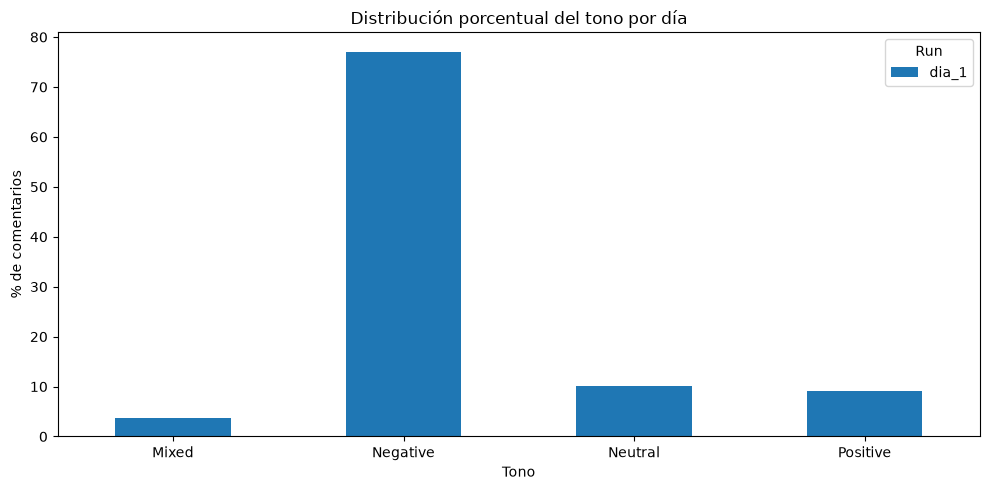

In [22]:
tone_pivot = (
    tone_counts
    .pivot(index="Tone", columns="run", values="pct")
    .fillna(0)
)

ax = tone_pivot.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Distribución porcentual del tono por día")
ax.set_xlabel("Tono")
ax.set_ylabel("% de comentarios")
ax.legend(title="Run")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Intención

`Intention` es multilabel: un mismo comentario puede contener varias categorías.

Por tanto, los porcentajes de las categorías **no tienen por qué sumar 100 %**. Aquí se calcula la proporción de comentarios de cada run que contiene cada etiqueta.


In [ ]:
intentions = (
    valid[["run", "comment_id", "Intention"]]
    .explode("Intention")
    .dropna(subset=["Intention"])
)

intention_counts = (
    intentions.groupby(["run", "Intention"])["comment_id"]
    .nunique()
    .rename("n_comments")
    .reset_index()
)

run_sizes = valid.groupby("run")["comment_id"].nunique()

intention_counts["pct_comments"] = intention_counts.apply(
    lambda row: 100 * row["n_comments"] / run_sizes.loc[row["run"]],
    axis=1
)

display(
    intention_counts.sort_values(
        ["run", "n_comments"],
        ascending=[True, False]
    )
)


In [ ]:
intention_pivot = (
    intention_counts
    .pivot(index="Intention", columns="run", values="pct_comments")
    .fillna(0)
    .sort_values(
        by=list(intention_counts["run"].unique()),
        ascending=False
    )
)

ax = intention_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Intenciones detectadas por día")
ax.set_xlabel("Intención")
ax.set_ylabel("% de comentarios que contienen la etiqueta")
ax.legend(title="Run")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 6. Metaconversación

Como también es una variable multilabel, se utiliza la misma lógica que con `Intention`.


In [ ]:
meta = (
    valid[["run", "comment_id", "Metaconversation"]]
    .explode("Metaconversation")
    .dropna(subset=["Metaconversation"])
)

meta_counts = (
    meta.groupby(["run", "Metaconversation"])["comment_id"]
    .nunique()
    .rename("n_comments")
    .reset_index()
)

meta_counts["pct_comments"] = meta_counts.apply(
    lambda row: 100 * row["n_comments"] / run_sizes.loc[row["run"]],
    axis=1
)

display(
    meta_counts.sort_values(
        ["run", "n_comments"],
        ascending=[True, False]
    )
)


In [ ]:
meta_plot = meta_counts[
    meta_counts["Metaconversation"] != "None"
].copy()

meta_pivot = (
    meta_plot
    .pivot(index="Metaconversation", columns="run", values="pct_comments")
    .fillna(0)
)

ax = meta_pivot.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("Metaconversación por día (sin 'None')")
ax.set_xlabel("Categoría")
ax.set_ylabel("% de comentarios que contienen la etiqueta")
ax.legend(title="Run")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 7. Emociones

`Emotion` también puede contener varias etiquetas. Una lista vacía significa que el modelo no asignó una emoción explícita.


In [ ]:
emotions = (
    valid[["run", "comment_id", "Emotion"]]
    .explode("Emotion")
    .dropna(subset=["Emotion"])
)

emotion_counts = (
    emotions.groupby(["run", "Emotion"])["comment_id"]
    .nunique()
    .rename("n_comments")
    .reset_index()
)

emotion_counts["pct_comments"] = emotion_counts.apply(
    lambda row: 100 * row["n_comments"] / run_sizes.loc[row["run"]],
    axis=1
)

display(
    emotion_counts.sort_values(
        ["run", "n_comments"],
        ascending=[True, False]
    ).head(40)
)


In [ ]:
top_emotions = (
    emotion_counts.groupby("Emotion")["n_comments"]
    .sum()
    .nlargest(15)
    .index
)

emotion_plot = emotion_counts[
    emotion_counts["Emotion"].isin(top_emotions)
]

emotion_pivot = (
    emotion_plot
    .pivot(index="Emotion", columns="run", values="pct_comments")
    .fillna(0)
)

ax = emotion_pivot.plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set_title("Emociones más frecuentes por día")
ax.set_xlabel("Emoción")
ax.set_ylabel("% de comentarios")
ax.legend(title="Run")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 8. Confianza del clasificador

Conviene observar tanto la distribución global como si ciertos tonos o categorías tienden a tener menor confianza.


In [ ]:
confidence_summary = (
    valid.groupby("run")["Confidence"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
)

display(confidence_summary)


In [ ]:
ax = valid.boxplot(
    column="Confidence",
    by="run",
    figsize=(9, 5)
)

plt.suptitle("")
plt.title("Confianza del clasificador por día")
plt.xlabel("Run")
plt.ylabel("Confidence")
plt.tight_layout()
plt.show()


In [ ]:
confidence_by_tone = (
    valid.groupby(["run", "Tone"])["Confidence"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(confidence_by_tone)


## 9. Tono a lo largo del día

Este análisis permite comprobar si el sentimiento del primer día fue estable o si cambió entre las primeras horas y las horas posteriores.

Se agrupa por hora UTC, que es la zona temporal utilizada en `published_at`.


In [ ]:
hourly_tone = (
    valid.groupby(["run", "hour", "Tone"])
    .size()
    .rename("n")
    .reset_index()
)

hourly_tone["pct_within_hour"] = (
    hourly_tone["n"]
    / hourly_tone.groupby(["run", "hour"])["n"].transform("sum")
    * 100
)

display(hourly_tone.head(20))


In [ ]:
for run_name in valid["run"].unique():
    tmp = (
        hourly_tone[hourly_tone["run"] == run_name]
        .pivot(index="hour", columns="Tone", values="pct_within_hour")
        .fillna(0)
    )

    ax = tmp.plot(
        figsize=(11, 5),
        marker="o"
    )

    ax.set_title(f"Evolución horaria del tono — {run_name}")
    ax.set_xlabel("Hora UTC")
    ax.set_ylabel("% dentro de la hora")
    ax.set_ylim(0, 100)

    plt.tight_layout()
    plt.show()


## 10. Popularidad y tono

Los likes y respuestas pueden servir como una medida aproximada de visibilidad o engagement.

Dado que estas variables suelen tener distribuciones muy asimétricas, se muestran mediana y media.


In [ ]:
engagement_by_tone = (
    valid.groupby(["run", "Tone"])
    .agg(
        n_comments=("comment_id", "size"),
        median_likes=("like_count", "median"),
        mean_likes=("like_count", "mean"),
        median_replies=("reply_count", "median"),
        mean_replies=("reply_count", "mean"),
    )
    .round(2)
)

display(engagement_by_tone)


## 11. Relación entre tono e intención

Esta tabla permite estudiar qué tipos de intención aparecen dentro de cada tono.

Como `Intention` es multilabel, cada comentario puede contribuir a varias filas.


In [ ]:
tone_intention = (
    valid[["run", "comment_id", "Tone", "Intention"]]
    .explode("Intention")
    .dropna(subset=["Intention"])
)

tone_intention_table = pd.crosstab(
    [tone_intention["run"], tone_intention["Tone"]],
    tone_intention["Intention"],
    normalize="index"
) * 100

display(tone_intention_table.round(1))


## 12. Comparación directa entre días

Esta sección cobra especial interés cuando estén disponibles los dos JSON.

La tabla resume las diferencias en puntos porcentuales del segundo día respecto al primero para `Tone`.


In [ ]:
if valid["run"].nunique() >= 2:
    tone_compare = (
        tone_counts
        .pivot(index="Tone", columns="run", values="pct")
        .fillna(0)
    )

    runs = list(existing_runs.keys())
    runs = [r for r in runs if r in tone_compare.columns]

    if len(runs) >= 2:
        tone_compare[f"{runs[1]} - {runs[0]} (pp)"] = (
            tone_compare[runs[1]] - tone_compare[runs[0]]
        )

    display(tone_compare.round(2))
else:
    print("Solo hay una run disponible. Añade el segundo JSON para activar esta comparación.")


## 13. Comentarios más representativos para inspección cualitativa

El análisis cuantitativo debería complementarse con una revisión manual de ejemplos.

Esta celda obtiene algunos comentarios de alta confianza para cada tono. No pretende validar el modelo estadísticamente, sino facilitar una inspección cualitativa rápida.


In [ ]:
examples = (
    valid.sort_values("Confidence", ascending=False)
    .groupby(["run", "Tone"], group_keys=False)
    .head(5)
    [[
        "run",
        "Tone",
        "Confidence",
        "like_count",
        "text",
        "Intention",
        "Metaconversation",
        "Emotion",
    ]]
)

display(examples)


## 14. Resumen compacto por run

Esta tabla sirve como cierre descriptivo antes de interpretar conjuntamente el análisis temporal del corpus y el análisis de sentimiento.


In [ ]:
summary_rows = []

for run_name, group in valid.groupby("run"):
    tone_pct = group["Tone"].value_counts(normalize=True) * 100

    summary_rows.append({
        "run": run_name,
        "n_valid": len(group),
        "negative_pct": tone_pct.get("Negative", 0),
        "positive_pct": tone_pct.get("Positive", 0),
        "neutral_pct": tone_pct.get("Neutral", 0),
        "mixed_pct": tone_pct.get("Mixed", 0),
        "median_confidence": group["Confidence"].median(),
        "mean_confidence": group["Confidence"].mean(),
        "median_likes": group["like_count"].median(),
        "mean_likes": group["like_count"].mean(),
    })

summary_df = pd.DataFrame(summary_rows).round(2)
display(summary_df)


## Interpretación futura

Cuando estén disponibles ambos días, conviene distinguir entre:

1. **composición del corpus**: cuántos comentarios se publicaron en cada día;
2. **composición del sentimiento**: qué proporción corresponde a cada tono;
3. **cambio discursivo**: si cambian intención, ironía, humor, fan culture, política, etc.;
4. **incertidumbre del clasificador**: si las diferencias entre días aparecen sobre todo en casos de confianza baja;
5. **engagement**: si ciertos tipos de comentario reciben más likes o respuestas.

Este análisis puede después combinarse con el notebook temporal del SQLite para decidir si los primeros días son discursivamente distintos y, por tanto, si deben tratarse como estratos específicos en una futura muestra.
